# Chọn vị trí trạm sạc xe điện bằng GIS: Nam và Bắc Từ Liêm

Chạy từ trên xuống dưới. Mở bằng môi trường `evgis`, từ **thư mục gốc của dự án** (nơi có file này).

| Phần | Việc làm | Ghi ra |
|---|---|---|
| 0 | Sửa DLL của môi trường, nạp thư viện, cài đặt | |
| 1 | Ranh giới hai quận | `du_lieu/area.gpkg` |
| 2 | Dữ liệu OpenStreetMap, trạm sạc nhập tay | `du_lieu/*.gpkg` |
| 3 | Dân số WorldPop | `du_lieu/pop_clip.tif` |
| 4 | Lưới 250 m và 5 tiêu chí | biến `grid` |
| 5 | Chuẩn hóa về thang 0-1 | cột `n_*` |
| 6 | Trọng số AHP | biến `w` |
| 7 | Chấm điểm, độ nhạy, kiểm chứng | cột `score`, `rank` |
| 8 | Xuất kết quả cho báo cáo | `ket_qua/` |
| 9 | Xuất dữ liệu cho trò chơi | `tro_choi/data.js` |

**Quy tắc dùng:**
- Mỗi lần Restart kernel, chạy lại từ ô đầu tiên (các bước tải về tự bỏ qua nếu file đã có, nên chạy lại rất nhanh).
- Mọi lựa chọn có thể chỉnh nằm trong ô **Cài đặt** ở phần 0, đừng sửa rải rác trong các ô sau.
- Sau khi đổi ranh giới hoặc đổi dữ liệu, các bước phụ thuộc sẽ tự tải lại khi file cũ hơn ranh giới.

## 0. Môi trường và cài đặt

**Ô 1: sửa lỗi kernel chết trên Windows.** Ép Python dùng đúng DLL của `evgis` thay vì DLL của PostgreSQL/QGIS. Luôn chạy ô này trước tiên.

In [1]:
# Ép sử dụng thư viện DLL của evgis (tránh kernel chết do xung đột DLL trên Windows)
import os, sys
import pyproj

env = sys.prefix                                   # thư mục môi trường evgis
lib = os.path.join(env, "Library")
os.environ["GDAL_DATA"] = os.path.join(lib, "share", "gdal")
os.environ["PROJ_DATA"] = pyproj.datadir.get_data_dir()
os.environ["PROJ_LIB"]  = os.environ["PROJ_DATA"]

# Đưa DLL của evgis lên đầu PATH, bỏ các thư mục dễ gây xung đột
mine = [env, os.path.join(lib, "bin"), os.path.join(lib, "mingw-w64", "bin"), os.path.join(env, "Scripts")]
rest = [p for p in os.environ["PATH"].split(os.pathsep)
        if not any(k in p.lower() for k in ("postgres", "qgis", "osgeo4w"))]
os.environ["PATH"] = os.pathsep.join(mine + rest)
print("Môi trường:", env)

Môi trường: c:\Users\DINHDUY_LAPTOP\anaconda3\envs\evgis


**Ô 2: nạp thư viện và cài đặt.** Mọi lựa chọn chỉnh được nằm ở đây.

In [ ]:
import os, json, time
import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import requests
import rasterio
from rasterio.mask import mask
from rasterstats import zonal_stats
from shapely.geometry import box
import matplotlib.pyplot as plt

# ===================== CÀI ĐẶT =====================
CRS = 32648                # UTM 48N, đơn vị mét, dùng cho mọi phép tính khoảng cách
SIZE = 250                 # cạnh ô lưới (m)
LOG_TRANSFORM = True       # dùng log1p cho dân số, chung cư, điểm đến (dữ liệu lệch phải nặng)

# Overpass chỉ chấp nhận client tự xưng danh: đặt tên dự án + liên hệ THẬT của bạn,
# KHÔNG giả làm trình duyệt (Mozilla/5.0...) vì sẽ bị trả mã 406.
UA = "tram-sac-xe-dien/1.0 (bai tap mon GIS; lien he: nguyendinhduy257@gmail.com)"

USE_HAND_DRAWN = False     # True: dùng du_lieu/area_hand.geojson thay vì tìm ranh giới trên OSM
FORCE_AREA = False         # True: tìm lại ranh giới dù đã có area.gpkg
FORCE_OSM = False          # True: tải lại dữ liệu OSM dù đã có (nhớ chạy lại ô gộp trạm sạc)
FORCE_POP = False          # True: cắt lại dân số dù đã có pop_clip.tif
DOWNLOAD_WORLDPOP = False  # True: tải file WorldPop bằng code (nặng hàng trăm MB, nên tải bằng trình duyệt)
# ===================================================

ox.settings.http_user_agent = UA
for d in ["du_lieu", "ket_qua", "bao_cao", "tro_choi"]:
    os.makedirs(d, exist_ok=True)
print("Thư mục làm việc:", os.getcwd())

Thư mục làm việc: d:\OneDrive\Desktop\Dự án cuối kỳ Hệ thống thông tin không gian GIS\tram_sac_xe_dien


## 1. Ranh giới khu vực

Hai quận không còn là đơn vị hành chính từ 01/7/2025, nên phải tìm bằng tên "District" của OSM. Nếu có sẵn `area.gpkg` thì nạp lại, không hỏi máy chủ nữa. Diện tích đúng khoảng **75 đến 78 km²** (Bắc khoảng 45, Nam khoảng 32). Nếu OSM không tìm được, vẽ tay trên https://geojson.io, lưu `du_lieu/area_hand.geojson` và đặt `USE_HAND_DRAWN = True`.

In [3]:
def find_area():
    if USE_HAND_DRAWN:
        return gpd.read_file("du_lieu/area_hand.geojson").to_crs(CRS).dissolve()
    bac = ox.geocode_to_gdf("Bắc Từ Liêm District, Hà Nội, Vietnam")
    nam = None
    for q in ["Nam Từ Liêm District, Hà Nội, Vietnam",
              "Nam Từ Liêm District, Hanoi, Vietnam",
              "Nam Tu Liem District, Hanoi, Vietnam"]:
        try:
            g = ox.geocode_to_gdf(q)
        except Exception as e:
            print(q, "-> LỖI:", e)
            continue
        a = g.to_crs(CRS).area[0] / 1e6
        print(q, "->", g.loc[0, "display_name"], "|", round(a, 1), "km2")
        if 25 < a < 40:                      # Nam Từ Liêm khoảng 32 km2
            nam = g
            break
    if nam is None:
        raise RuntimeError("Không tìm được Nam Từ Liêm trên OSM: vẽ tay và đặt USE_HAND_DRAWN = True")
    return gpd.GeoDataFrame(pd.concat([bac, nam], ignore_index=True), crs=bac.crs).dissolve().to_crs(CRS)

AREA_FILE = "du_lieu/area.gpkg"
if os.path.exists(AREA_FILE) and not FORCE_AREA and not USE_HAND_DRAWN:
    area = gpd.read_file(AREA_FILE).to_crs(CRS)
    print("Đã nạp ranh giới có sẵn:", AREA_FILE)
else:
    area = find_area()[["geometry"]]
    area.to_file(AREA_FILE, driver="GPKG")
    print("Đã lưu", AREA_FILE)

km2 = area.area.sum() / 1e6
print("Diện tích (km2):", round(km2, 1), "(kỳ vọng khoảng 75-78)")
if not 70 < km2 < 85:
    print("CẢNH BÁO: diện tích lệch nhiều, kiểm tra lại ranh giới trước khi chạy tiếp")
area.to_crs(4326).explore()

Đã nạp ranh giới có sẵn: du_lieu/area.gpkg
Diện tích (km2): 77.2 (kỳ vọng khoảng 75-78)


## 2. Dữ liệu OpenStreetMap

Tải mạng đường và các lớp trạm sạc, chung cư, điểm đến, mặt nước qua Overpass. **Bỏ qua tự động** nếu đã có đủ 5 file và chúng mới hơn ranh giới. Nếu máy chủ trả 406, ô sẽ tự đổi sang máy chủ khác (nguyên nhân thường gặp: User-Agent giả trình duyệt hoặc để mặc định, xem ô Cài đặt).

Danh sách tag chỉ là gợi ý ban đầu, kiểm tra tag có dữ liệu bằng https://overpass-turbo.eu nếu số lượng in ra quá ít.

In [4]:
OSM_FILES = ["roads_main", "charging", "apartments", "poi", "water"]

def osm_up_to_date():
    paths = [f"du_lieu/{n}.gpkg" for n in OSM_FILES]
    if not all(os.path.exists(p) for p in paths):
        return False
    t_area = os.path.getmtime(AREA_FILE)
    return all(os.path.getmtime(p) >= t_area for p in paths)

def download_osm():
    ox.settings.use_cache = True
    ox.settings.requests_timeout = 180
    headers = {"User-Agent": UA, "Accept": "*/*"}
    poly = area.to_crs(4326).geometry.union_all()      # geopandas từ 1.0; bản cũ dùng unary_union
    endpoints = [
        "https://overpass-api.de/api/interpreter",
        "https://overpass.private.coffee/api/interpreter",
        "https://overpass.kumi.systems/api/interpreter",
    ]
    full = str(ox.settings.overpass_url).rstrip("/").endswith("interpreter")
    cur = {"i": 0}

    def use(start):
        for k in range(len(endpoints)):
            i = (start + k) % len(endpoints)
            u = endpoints[i]
            try:
                r = requests.post(u, data={"data": "[out:json][timeout:25];node(1);out;"},
                                  headers=headers, timeout=40)
                print(u, "-> HTTP", r.status_code)
                if r.status_code == 200:
                    ox.settings.overpass_url = u if full else u.rsplit("/interpreter", 1)[0]
                    cur["i"] = i
                    return
            except Exception as e:
                print(u, "->", type(e).__name__)
        raise RuntimeError("Không máy chủ Overpass nào trả HTTP 200, xem các dòng HTTP phía trên")

    retryable = ("406", "429", "502", "503", "504", "capacity", "queue is full",
                 "timed out", "timeout", "connection", "max retries")

    def run(label, fn):
        for attempt in range(4):
            try:
                return fn()
            except Exception as e:
                msg = str(e).lower()
                if attempt == 3 or not any(p in msg for p in retryable):
                    raise
                wait = 30 * 2 ** attempt
                print(f"{label}: lỗi tạm thời ({type(e).__name__}); chờ {wait} giây, đổi máy chủ...")
                time.sleep(wait)
                use(cur["i"] + 1)

    use(0)

    G = run("mạng đường", lambda: ox.graph_from_polygon(poly, network_type="drive", simplify=True))
    edges = ox.graph_to_gdfs(G, nodes=False)
    edges["highway"] = edges["highway"].map(lambda v: v[0] if isinstance(v, list) else v)
    main = edges[edges["highway"].isin(["motorway", "trunk", "primary", "secondary"])]
    main.to_crs(CRS)[["highway", "geometry"]].to_file("du_lieu/roads_main.gpkg", driver="GPKG")
    print("roads_main", len(main))

    tags = {
        "charging":   {"amenity": "charging_station"},
        "apartments": {"building": "apartments"},
        "poi": {
            "shop": ["mall", "supermarket", "department_store"],
            "amenity": ["university", "college", "marketplace"],
            "leisure": ["stadium", "sports_centre"],
        },
        "water":      {"natural": "water"},
    }
    for name, t in tags.items():
        g = run(name, lambda: ox.features_from_polygon(poly, tags=t)).to_crs(CRS)
        if name == "water":
            g = g[g.geom_type.isin(["Polygon", "MultiPolygon"])]
        else:
            g["geometry"] = g.geometry.centroid
        g[["geometry"]].to_file(f"du_lieu/{name}.gpkg", driver="GPKG")
        print(name, len(g))

if osm_up_to_date() and not FORCE_OSM:
    print("Đã có đủ dữ liệu OSM (mới hơn ranh giới), bỏ qua bước tải.")
else:
    download_osm()

https://overpass-api.de/api/interpreter -> HTTP 200
roads_main 1335
charging: lỗi tạm thời (ResponseStatusCodeError); chờ 30 giây, đổi máy chủ...
https://overpass.private.coffee/api/interpreter -> ReadTimeout
https://overpass.kumi.systems/api/interpreter -> ReadTimeout
https://overpass-api.de/api/interpreter -> HTTP 200
charging 47
apartments 366
poi 129
water 211


**Gộp trạm sạc nhập tay (tùy chọn).** Nếu OSM thiếu trạm, điền `du_lieu/charging_manual.csv` với 3 cột đúng thứ tự tên là `name,lat,lon` (vĩ độ khoảng 21, kinh độ khoảng 105; tên có dấu phẩy phải bọc trong ngoặc kép). Ô này chạy lại bao nhiêu lần cũng được: các điểm trùng nhau (cách nhau dưới khoảng 5 m) tự bị gộp.

In [5]:
st = gpd.read_file("du_lieu/charging.gpkg")[["geometry"]].to_crs(CRS)
n_osm = len(st)

csv_path = "du_lieu/charging_manual.csv"
if os.path.exists(csv_path):
    m = pd.read_csv(csv_path).dropna(subset=["lat", "lon"])
    if len(m):
        manual = gpd.GeoDataFrame(geometry=gpd.points_from_xy(m["lon"], m["lat"]), crs=4326).to_crs(CRS)
        st = pd.concat([st, manual[["geometry"]]], ignore_index=True)

st["k"] = st.geometry.apply(lambda p: (round(p.x / 5), round(p.y / 5)))
st = st.drop_duplicates("k")
st = gpd.GeoDataFrame(st[["geometry"]], geometry="geometry", crs=CRS)
st.to_file("du_lieu/charging.gpkg", driver="GPKG")
print("Trạm sạc sau khi gộp và bỏ trùng:", len(st), "(trước đó:", n_osm, ")")

Trạm sạc sau khi gộp và bỏ trùng: 328 (trước đó: 47 )


## 3. Dân số WorldPop

Cần file `du_lieu/vnm_ppp_2020.tif` (WorldPop, Vietnam, 2020, 100 m, tải bằng trình duyệt). Ô này cắt theo ranh giới và **tự cắt lại** nếu `pop_clip.tif` cũ hơn ranh giới.

In [6]:
POP_SRC = "du_lieu/vnm_ppp_2020.tif"
POP_CLIP = "du_lieu/pop_clip.tif"
POP_URL = "https://data.worldpop.org/GIS/Population/Global_2000_2020/2020/VNM/vnm_ppp_2020.tif"

stale = (not os.path.exists(POP_CLIP)) or os.path.getmtime(POP_CLIP) < os.path.getmtime(AREA_FILE)
if stale or FORCE_POP:
    if DOWNLOAD_WORLDPOP and not os.path.exists(POP_SRC):
        import urllib.request
        urllib.request.urlretrieve(POP_URL, POP_SRC)
    with rasterio.open(POP_SRC) as src:
        out, tf = mask(src, area.to_crs(4326).geometry, crop=True)
        meta = src.meta.copy()
    meta.update(height=out.shape[1], width=out.shape[2], transform=tf)
    with rasterio.open(POP_CLIP, "w", **meta) as dst:
        dst.write(out)
    print("Đã cắt dân số theo ranh giới hiện tại")
else:
    print("pop_clip.tif còn mới, bỏ qua bước cắt.")

with rasterio.open(POP_CLIP) as src:
    print("Tổng dân số ước lượng:", int(src.read(1, masked=True).sum()), "(kỳ vọng vài trăm nghìn)")

Đã cắt dân số theo ranh giới hiện tại
Tổng dân số ước lượng: 520288 (kỳ vọng vài trăm nghìn)


## 4. Lưới và tiêu chí

Mỗi ô 250 m là một vị trí ứng viên: dân số trong ô, số chung cư và điểm đến trong 500 m, khoảng cách tới đường trục chính và tới trạm sạc gần nhất (mét), và cờ `excluded` cho ô bị nước phủ trên 50%. Số ô đúng khoảng **1.200 đến 1.300**.

In [7]:
minx, miny, maxx, maxy = area.total_bounds
cells_geom = [box(x, y, x + SIZE, y + SIZE)
              for x in np.arange(minx, maxx, SIZE) for y in np.arange(miny, maxy, SIZE)]
grid = gpd.GeoDataFrame(geometry=cells_geom, crs=CRS)
grid = grid[grid.intersects(area.union_all())].reset_index(drop=True)
grid["cell_id"] = grid.index
cent = grid.geometry.centroid
print("Số ô:", len(grid))

Số ô: 1371


Số ô: 1371 | số ô bị loại: 82
            count         mean          std        min         25%  \
pop        1371.0   379.495374   248.147950   0.000000  207.906540   
apt        1371.0     3.273523     6.011694   0.000000    0.000000   
poi        1371.0     1.132020     1.683129   0.000000    0.000000   
d_road     1371.0   351.462630   286.524053   0.108304  127.912254   
d_charger  1371.0  1640.634505  1391.712159  17.381045  596.346674   

                   50%          75%          max  
pop         339.833160   512.094482  1701.993164  
apt           0.000000     4.000000    48.000000  
poi           1.000000     2.000000    12.000000  
d_road      281.367404   507.881329  1552.642357  
d_charger  1097.707285  2458.219702  5801.639252  


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

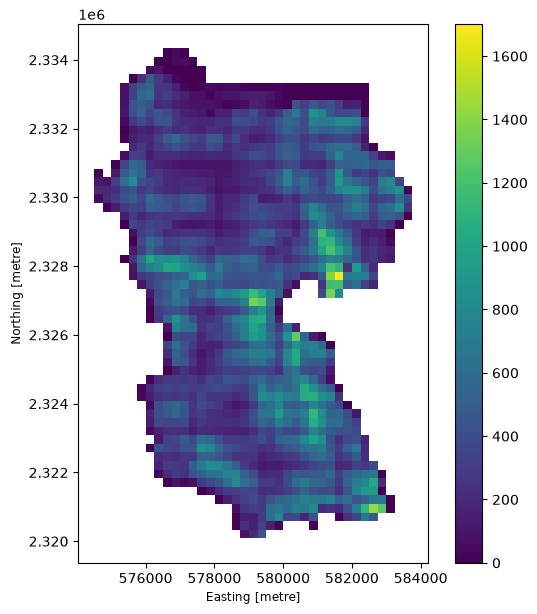

In [8]:
# Dân số: zonal_stats cần cùng hệ tọa độ với raster nên đưa lưới về 4326
zs = zonal_stats(grid.to_crs(4326), POP_CLIP, stats=["sum"])
grid["pop"] = [z["sum"] or 0 for z in zs]

# Đếm điểm trong bán kính 500 m quanh tâm ô
def count_within(path, radius=500):
    pts = gpd.read_file(path).to_crs(CRS)
    buf = gpd.GeoDataFrame({"cell_id": grid["cell_id"]}, geometry=cent.buffer(radius), crs=CRS)
    j = gpd.sjoin(pts, buf, predicate="within")
    return grid["cell_id"].map(j.groupby("cell_id").size()).fillna(0)

grid["apt"] = count_within("du_lieu/apartments.gpkg")
grid["poi"] = count_within("du_lieu/poi.gpkg")

# Khoảng cách (mét)
roads = gpd.read_file("du_lieu/roads_main.gpkg").to_crs(CRS).union_all()
stations = gpd.read_file("du_lieu/charging.gpkg").to_crs(CRS).union_all()
grid["d_road"] = cent.distance(roads)
grid["d_charger"] = cent.distance(stations)

# Loại trừ: ô bị nước phủ trên 50% (thêm điều kiện khác ở đây nếu cần)
water = gpd.read_file("du_lieu/water.gpkg").to_crs(CRS).union_all()
grid["excluded"] = grid.intersection(water).area > 0.5 * grid.area

print("Số ô:", len(grid), "| số ô bị loại:", int(grid["excluded"].sum()))
print(grid[["pop", "apt", "poi", "d_road", "d_charger"]].describe().T)
grid.plot(column="pop", legend=True, figsize=(7, 7))

## 5. Chuẩn hóa về thang 0-1

Cắt ở phân vị 5 và 95 để vài ô cực đoan không làm lệch thang. Dân số, chung cư, điểm đến lệch phải nặng nên mặc định dùng `log1p` trước khi chuẩn hóa (`LOG_TRANSFORM` ở ô Cài đặt). `d_road` đảo chiều (càng gần càng tốt). `d_charger` dùng trần 2 km (xa hơn coi như tốt như nhau). **Ghi các lựa chọn này vào báo cáo.**

Trò chơi `tro_choi/index.html` đọc cờ `LOG_TRANSFORM` ở phần 9 nên điểm trên bản đồ khớp với notebook.

array([[<Axes: title={'center': 'n_pop'}>,
        <Axes: title={'center': 'n_apt'}>],
       [<Axes: title={'center': 'n_poi'}>,
        <Axes: title={'center': 'n_road'}>],
       [<Axes: title={'center': 'n_charger'}>, <Axes: >]], dtype=object)

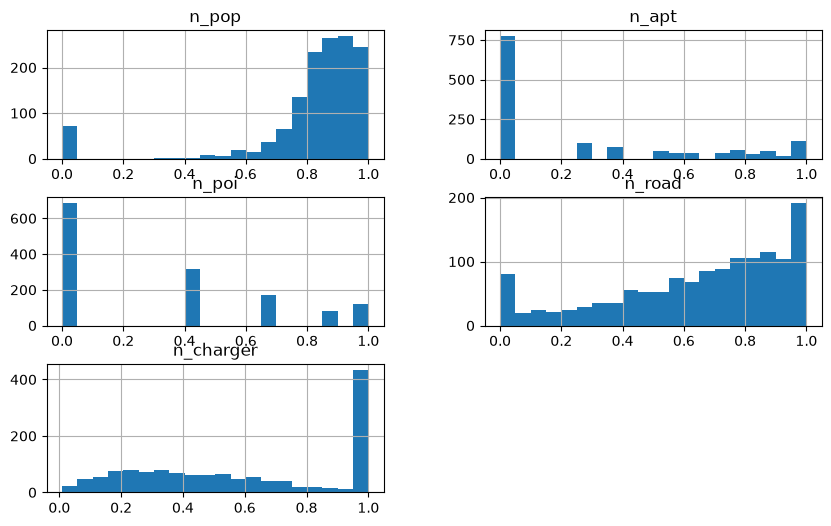

In [9]:
def minmax(s, lo=5, hi=95):
    a, b = np.percentile(s, [lo, hi])
    if b == a:
        return s * 0
    return (s.clip(a, b) - a) / (b - a)

def prep(s):
    return np.log1p(s) if LOG_TRANSFORM else s

grid["n_pop"] = minmax(prep(grid["pop"]))
grid["n_apt"] = minmax(prep(grid["apt"]))
grid["n_poi"] = minmax(prep(grid["poi"]))
grid["n_road"] = 1 - minmax(grid["d_road"])                        # càng gần càng tốt
grid["n_charger"] = np.minimum(grid["d_charger"], 2000) / 2000     # càng xa càng tốt, trần 2 km

NORM = ["n_pop", "n_apt", "n_poi", "n_road", "n_charger"]
grid[NORM].hist(bins=20, figsize=(10, 6))

## 6. Trọng số AHP

So sánh từng cặp tiêu chí theo thang 1, 3, 5, 7, 9 (và nghịch đảo): 3 nghĩa là tiêu chí hàng quan trọng hơn tiêu chí cột "một chút", 9 là "tuyệt đối". Thứ tự: `pop, apt, poi, road, charger`. Cần **CR nhỏ hơn 0,1**; nếu không, xem lại các cặp so sánh mâu thuẫn.

**Ma trận dưới chỉ là ví dụ minh họa.** Hãy tự điền theo đánh giá của bạn, và tốt nhất hỏi thêm 3 đến 5 người rồi gộp bằng `M = geo_mean([M1, M2, M3])` để có căn cứ khi bị hỏi vặn trọng số.

In [10]:
RI = [0, 0, 0.58, 0.90, 1.12, 1.24, 1.32, 1.41, 1.45, 1.49]

def ahp(M):
    M = np.array(M, dtype=float)
    n = len(M)
    vals, vecs = np.linalg.eig(M)
    k = np.argmax(vals.real)
    w = np.abs(vecs[:, k].real)
    w = w / w.sum()
    ci = (vals[k].real - n) / (n - 1)
    return w, (ci / RI[n - 1] if RI[n - 1] else 0)

def geo_mean(matrices):
    return np.exp(np.mean(np.log(np.array(matrices)), axis=0))

M = [
    [1,   2,   3,   3,   2],
    [1/2, 1,   2,   2,   1],
    [1/3, 1/2, 1,   1,   1/2],
    [1/3, 1/2, 1,   1,   1/2],
    [1/2, 1,   2,   2,   1],
]
w, cr = ahp(M)
print("Trọng số:", dict(zip(["pop", "apt", "poi", "road", "charger"], w.round(3))))
print("CR =", round(cr, 3), "(đạt nếu < 0.1)")

Trọng số: {'pop': np.float64(0.369), 'apt': np.float64(0.206), 'poi': np.float64(0.109), 'road': np.float64(0.109), 'charger': np.float64(0.206)}
CR = 0.003 (đạt nếu < 0.1)


## 7. Chấm điểm, độ nhạy, kiểm chứng

- **Chấm điểm:** tổng có trọng số các tiêu chí đã chuẩn hóa, ô `excluded` bị loại.
- **Độ nhạy:** nhiễu trọng số cộng trừ 20% một nghìn lần, đếm số lần mỗi ô vào top 10. Ô vào top 10 trên 80% số lần là vị trí vững.
- **Kiểm chứng:** tính lại điểm chỉ từ bốn tiêu chí đầu (bỏ `n_charger`, vì trạm đang có bị phạt điểm giả tạo), rồi xem các trạm hiện có nằm ở phân vị nào. Phân vị cao nghĩa là mô hình nhận ra đúng các khu hợp lý. Nếu thấp, hãy thảo luận nguyên nhân trong báo cáo.

In [11]:
X = grid[NORM].values
grid["score"] = X @ w
grid.loc[grid["excluded"], "score"] = np.nan
grid["rank"] = grid["score"].rank(ascending=False, method="min")

# Độ nhạy
rng = np.random.default_rng(42)
ok = ~grid["excluded"].values
Xok = X[ok]
hits = np.zeros(ok.sum())
N = 1000
for _ in range(N):
    wp = w * rng.uniform(0.8, 1.2, size=len(w))
    wp = wp / wp.sum()
    hits[np.argsort(-(Xok @ wp))[:10]] += 1
grid["top10_freq"] = np.nan
grid.loc[ok, "top10_freq"] = hits / N
print("Số ô vào top 10 trên 80% số lần thử:", int((grid["top10_freq"] > 0.8).sum()))

# Kiểm chứng bằng trạm sạc đang có
st = gpd.read_file("du_lieu/charging.gpkg").to_crs(CRS)
w4 = w[:4] / w[:4].sum()
grid["demand"] = grid[NORM[:4]].values @ w4
grid.loc[grid["excluded"], "demand"] = np.nan
grid["demand_pct"] = grid["demand"].rank(pct=True)
j = gpd.sjoin(st, grid[["cell_id", "demand_pct", "geometry"]], predicate="within")
print("Phân vị trung bình của các ô có trạm sạc:", round(j["demand_pct"].mean(), 2))

Số ô vào top 10 trên 80% số lần thử: 7
Phân vị trung bình của các ô có trạm sạc: 0.77


## 8. Xuất kết quả cho báo cáo

Ba file trong `ket_qua/`: bản đồ tương tác (mở bằng trình duyệt), danh sách top 10 kèm tọa độ để tra Google Maps, và biểu đồ độ nhạy.

,rank,cell_id,score,top10_freq,pop,apt,poi,d_road,d_charger,lat,lon
1190,1.0,1190,0.876702,0.977,810.728027,7.0,1.0,22.873441,1926.173341,21.08910,105.78589
1189,2.0,1189,0.876424,0.999,595.831787,13.0,1.0,9.737259,1676.377813,21.08684,105.78588
1171,3.0,1171,0.870244,0.975,1194.612305,17.0,5.0,8.686449,741.848669,21.04618,105.78567
914,4.0,914,0.869514,0.995,737.730530,35.0,7.0,620.926237,1489.211884,21.07561,105.77138
913,5.0,913,0.866107,0.954,740.065918,48.0,7.0,606.546366,1438.002387,21.07335,105.77137
1248,6.0,1248,0.864777,0.959,913.555420,16.0,2.0,73.632080,1090.426731,21.05068,105.79050
1005,7.0,1005,0.861354,0.888,585.192627,43.0,12.0,106.791460,943.669662,21.07333,105.77618
1104,8.0,1104,0.860184,0.643,697.874451,5.0,3.0,349.698725,1971.669895,21.08912,105.78108
1148,9.0,1148,0.858039,0.631,518.557373,10.0,2.0,195.623725,1684.165013,21.08685,105.78347
1004,10.0,1004,0.856787,0.661,540.039429,26.0,11.0,96.611258,930.382320,21.07107,105.77617


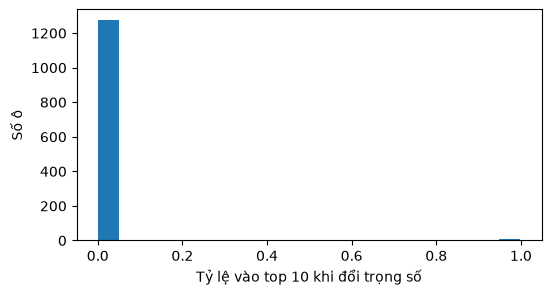

In [12]:
top10 = grid.nsmallest(10, "rank").copy()
c = top10.geometry.centroid.to_crs(4326)
top10["lat"], top10["lon"] = c.y.round(5), c.x.round(5)
cols = ["rank", "cell_id", "score", "top10_freq", "pop", "apt", "poi", "d_road", "d_charger", "lat", "lon"]
top10[cols].to_csv("ket_qua/top10.csv", index=False, encoding="utf-8-sig")

m = grid.to_crs(4326).explore(
    column="score", cmap="YlOrRd", tiles="OpenStreetMap",
    tooltip=["rank", "score", "pop", "apt", "poi", "d_road", "d_charger"],
    missing_kwds={"color": "lightgrey"}, style_kwds={"weight": 0.3, "fillOpacity": 0.6},
)
top10.to_crs(4326).explore(m=m, color="#0b3d91", style_kwds={"fill": False, "weight": 3})
m.save("ket_qua/ban_do.html")

plt.figure(figsize=(6, 3))
plt.hist(grid["top10_freq"].dropna(), bins=20)
plt.xlabel("Tỷ lệ vào top 10 khi đổi trọng số")
plt.ylabel("Số ô")
plt.savefig("ket_qua/do_nhay.png", dpi=150, bbox_inches="tight")

top10[cols]

## 9. Xuất dữ liệu cho trò chơi

Ghi `tro_choi/data.js` (đọc bởi `tro_choi/index.html`). Sau khi chạy xong, mở `index.html` rồi nhấn Ctrl + F5. Ô này cũng in phân bố 6 mức điểm để bạn kiểm tra ngưỡng màu `CUT` trong `index.html` (mặc định 20, 35, 50, 65, 80).

In [13]:
g = grid.to_crs(4326)
game_cells = []
for geom, r in zip(g.geometry, grid.itertuples()):
    ring = list(geom.exterior.coords)[:4]
    cen = geom.centroid
    game_cells.append({
        "c": [round(cen.y, 5), round(cen.x, 5)],
        "p": [round(v, 5) for lon, lat in ring for v in (lat, lon)],
        "v": [round(r.pop), int(r.apt), int(r.poi), round(r.d_road), round(r.d_charger)],
        "x": int(r.excluded),
    })

st4326 = gpd.read_file("du_lieu/charging.gpkg").to_crs(4326)
area_geo = area.to_crs(4326).geometry.simplify(0.0003).iloc[0]
data = {
    "log": bool(LOG_TRANSFORM),
    "weights": dict(zip(["pop", "apt", "poi", "road", "charger"], [round(float(x), 4) for x in w])),
    "area": json.loads(gpd.GeoSeries([area_geo]).to_json())["features"][0]["geometry"],
    "stations": [[round(p.y, 5), round(p.x, 5)] for p in st4326.geometry],
    "cells": game_cells,
}
with open("tro_choi/data.js", "w", encoding="utf-8") as f:
    f.write("window.GAME_DATA=" + json.dumps(data, ensure_ascii=False, separators=(",", ":")) + ";")
print(len(game_cells), "ô đã xuất vào tro_choi/data.js")

# Xem trước phân bố 6 mức điểm (thang 0-100, cùng ngưỡng với index.html)
CUT = [20, 35, 50, 65, 80]
LEVELS = ["Thấp", "Trung bình thấp", "Trung bình", "Trung bình tốt", "Tốt", "Rất tốt"]
lv = np.digitize(grid["score"].dropna() * 100, CUT)
print(pd.Series(lv).map(dict(enumerate(LEVELS))).value_counts().reindex(LEVELS))

1371 ô đã xuất vào tro_choi/data.js
Thấp                 7
Trung bình thấp     32
Trung bình         196
Trung bình tốt     629
Tốt                351
Rất tốt             74
Name: count, dtype: int64
